Saving Screenshot 2026-11-21 175022.png to Screenshot 2026-11-21 175022.png
ARITHMETIC ENCODING RESULTS
---------------------------------------------
Image Dimensions: 283 x 367
Total Pixels: 103861
Unique Pixel Values: 233

Pixel Probabilities:
Pixel 0: Frequency = 14368, Probability = 0.138339
Pixel 1: Frequency = 3, Probability = 0.000029
Pixel 2: Frequency = 4, Probability = 0.000039
Pixel 3: Frequency = 18, Probability = 0.000173
Pixel 4: Frequency = 48, Probability = 0.000462
Pixel 5: Frequency = 93, Probability = 0.000895
Pixel 6: Frequency = 252, Probability = 0.002426
Pixel 7: Frequency = 3014, Probability = 0.029020
Pixel 8: Frequency = 255, Probability = 0.002455
Pixel 9: Frequency = 104, Probability = 0.001001
Pixel 10: Frequency = 66, Probability = 0.000635
Pixel 11: Frequency = 45, Probability = 0.000433
Pixel 12: Frequency = 12, Probability = 0.000116
Pixel 13: Frequency = 18, Probability = 0.000173
Pixel 14: Frequency = 10, Probability = 0.000096
Pixel 15: Frequency = 1

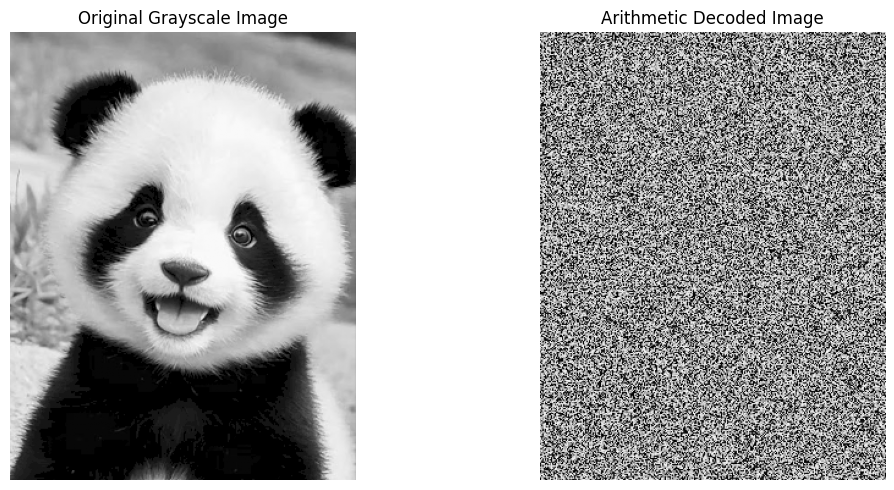


Decoded image saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from collections import Counter
import heapq

# STEP 1: Upload Image
uploaded = files.upload()
image_name = list(uploaded.keys())[0]

# STEP 2: Read Image and Convert to Grayscale
image = cv2.imdecode(
    np.frombuffer(uploaded[image_name], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    raise ValueError("Unable to read the uploaded image.")

height, width = image.shape
pixels = image.flatten().tolist()

# STEP 3: Calculate Frequency and Probability
frequency = Counter(pixels)
total_pixels = len(pixels)

probability = {
    symbol: count / total_pixels
    for symbol, count in frequency.items()
}

# STEP 4: Create Cumulative Probability Table
symbols = sorted(probability.keys())

cumulative = {}
low = 0.0

for symbol in symbols:
    high = low + probability[symbol]
    cumulative[symbol] = (low, high)
    low = high

# STEP 5: Arithmetic Encoding
def arithmetic_encode(data):
    low = 0.0
    high = 1.0

    for symbol in data:
        range_value = high - low
        symbol_low, symbol_high = cumulative[symbol]

        high = low + range_value * symbol_high
        low = low + range_value * symbol_low

    encoded_value = (low + high) / 2

    return encoded_value, low, high

encoded_value, final_low, final_high = arithmetic_encode(pixels)

# STEP 6: Arithmetic Decoding
def arithmetic_decode(encoded_value, length):
    decoded = []

    for _ in range(length):
        for symbol in symbols:
            symbol_low, symbol_high = cumulative[symbol]

            if symbol_low <= encoded_value < symbol_high:
                decoded.append(symbol)

                encoded_value = (
                    encoded_value - symbol_low
                ) / (symbol_high - symbol_low)

                break

    return decoded

decoded_pixels = arithmetic_decode(
    encoded_value,
    total_pixels
)

# STEP 7: Reconstruct Image
decoded_image = np.array(
    decoded_pixels,
    dtype=np.uint8
).reshape(height, width)

# STEP 8: Calculate Encoding Information
print("ARITHMETIC ENCODING RESULTS")
print("-" * 45)

print("Image Dimensions:", width, "x", height)
print("Total Pixels:", total_pixels)
print("Unique Pixel Values:", len(frequency))

print("\nPixel Probabilities:")
for symbol in symbols:
    print(
        f"Pixel {symbol}: "
        f"Frequency = {frequency[symbol]}, "
        f"Probability = {probability[symbol]:.6f}"
    )

print("\nFinal Arithmetic Interval:")
print("Lower Bound:", format(final_low, ".15f"))
print("Upper Bound:", format(final_high, ".15f"))
print("Encoded Value:", format(encoded_value, ".15f"))

# STEP 9: Calculate Theoretical Encoding Size
# Shannon information content in bits
theoretical_bits = -sum(
    frequency[symbol] * np.log2(probability[symbol])
    for symbol in symbols
)

original_bits = total_pixels * 8

# Approximate ideal arithmetic coding size
compressed_bits = int(np.ceil(theoretical_bits)) + 1

compression_ratio = original_bits / compressed_bits
space_saving = (
    (original_bits - compressed_bits) / original_bits
) * 100

print("\nCOMPRESSION DETAILS")
print("-" * 45)

print("Original Image Size (bits):", original_bits)
print("Theoretical Information (bits):", round(theoretical_bits, 2))
print("Estimated Encoded Size (bits):", compressed_bits)
print("Estimated Compression Ratio:", round(compression_ratio, 3))
print("Estimated Space Saving:", round(space_saving, 2), "%")

# STEP 10: Verify Decoding
if np.array_equal(image, decoded_image):
    print("\nImage Decoding: SUCCESS")
    print("Original and decoded images are identical.")
else:
    print("\nImage Decoding: FAILED")

# STEP 11: Display Original and Decoded Images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(decoded_image, cmap="gray")
plt.title("Arithmetic Decoded Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 12: Save Reconstructed Image
cv2.imwrite("Arithmetic_Decoded_Image.png", decoded_image)

print("\nDecoded image saved successfully.")

files.download("Arithmetic_Decoded_Image.png")